In [1]:
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym

eps = 1E-7
rcpsize = 18
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
markers = ['*','o','h','^','s','p']
linestyles=['-','--']

In [10]:
models = [
          'deepseek',
          'llama',
          ]

n_files = 500
batch_size = 10 
Ns = batch_size*n_files
mask = 2
# n_tokens_list = np.arange(1,15+1,2,dtype=int)
# n_tokens_list = np.concatenate((n_tokens_list,
#                                 np.array([20,25,30,35,38]))
#                                 )
n_tokens_lists = [np.array([1,5,10,15,20,25,30,35,38]),
                           np.array([1,5,10,20,30,40,50,60,70,80,90,98])
                           ]
                
min_token_lengths = [40,100]
# n_tokens_list = )
# min_token_length = 40

language_pairs = [('english','spanish'),
                #   ('german','hungarian'),
                  ]

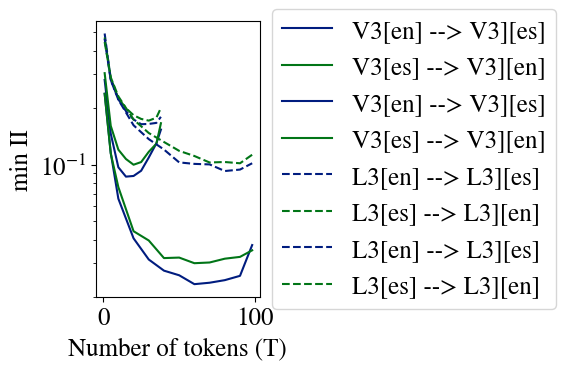

In [11]:
fig,ax = plt.subplots(1,figsize=(6,4))
Nbits = 0 
avg = 0
k = 10
figsfolder = makefolder(base=f'./results/figs/n_tokens_dependence/',
                            create_folder=True,
                            n_files=n_files,
                            )

for model_id,model in enumerate(models):
  if model == 'deepseek':
    _model = 'V3'
  elif model =='llama':
    _model = 'L3'
  for min_token_length_id,min_token_length in enumerate(min_token_lengths):
    n_tokens_list = n_tokens_lists[min_token_length_id]
    for language_pair in language_pairs:
      (languageA,languageB) = language_pair
      min_II_AB = np.zeros(shape=n_tokens_list.shape[0])
      min_II_BA = np.zeros(shape=n_tokens_list.shape[0])
      min_IIs = np.zeros(shape=n_tokens_list.shape[0])
      for n_tokens_id,n_tokens in enumerate(n_tokens_list):
        II_folder = makefolder(base=f'./results/santiago/',
                                  modelA=model,
                                  modelB=model,
                                  n_files=n_files,
                                  min_token_length=min_token_length,
                                  languageA=languageA,
                                  languageB=languageB,
                                  mask=mask,
                                  k=k,
                                  Nbits=Nbits,
                                  )
        IIAB = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_AB.npy').diagonal()
        IIBA = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_BA.npy').diagonal()
        IIs = np.array([IIAB,IIBA])
        min_II_AB[n_tokens_id] = np.min(IIs[0])
        min_II_BA[n_tokens_id] = np.min(IIs[1])
        min_IIs[n_tokens_id] = np.min(IIs)

      
      ax.plot(n_tokens_list,
              min_II_AB,
              color=colors[0],
              linestyle=linestyles[model_id],
              label=f'{_model}[{get_acronym(languageA)}] --> {_model}][{get_acronym(languageB)}]'
              )
      ax.plot(n_tokens_list,
              min_II_BA,
              color=colors[1],
              label=f'{_model}[{get_acronym(languageB)}] --> {_model}][{get_acronym(languageA)}]',
              linestyle=linestyles[model_id],
              )
      np.savetxt(figsfolder+f'{model}_min_II_AB_{n_tokens}.txt',np.array([n_tokens_list,min_II_AB]).T)
      np.savetxt(figsfolder+f'{model}_min_II_BA_{n_tokens}.txt',np.array([n_tokens_list,min_II_BA]).T)
      
      ax.set_xlabel('Number of tokens (T)')
      ax.set_ylabel(f'min II')
      # ax.set_title(f' {languageA} - {languageB}')
      
      box = ax.get_position()
      ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
      ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
      # ax.set_yscale('log')
      ax.hlines(0,0,n_tokens,color='gray',linestyles='dashed')

ax.set_yscale('log')

fig.savefig(figsfolder + f'n_tokens_dependence.pdf',bbox_inches='tight')
plt.show()